# Notebook 4: Query log analysis (`history/last_month/query_log.csv.gz`)

This notebook is a detailed look at last month's workload. I wanted to understand who sent what and when, how long queries waited and ran, which SLAs were missed and why, how traffic changes over time, how predictable runtimes are, how the historical scheduler routed queries, and whether any queries were retried.

This is the only dataset that describes individual queries, so it matters a lot for the scheduler. It answers Part 1 questions 2 and 3 of the assignment (the cost and penalties for each client, and the traffic patterns that matter for scheduling). It also gives me the evidence behind the scheduler's routing, priority and runtime-prediction choices.

To understand the file, I checked the simulator source. `simkit/engine.py` writes one row per query when it **completes** (`_on_complete`) or is **dropped or rejected** (`_drop`):

| column | meaning (from the code) |
|---|---|
| `query_id` | the id from the traffic file |
| `client_id`, `query_type`, `template_id` | from the traffic file; queries with the same `template_id` are repeats of the same SQL (README) |
| `arrival_s` | when the query arrived |
| `start_s` | when its **final** attempt started running |
| `end_s` | when it completed |
| `wait_s` | `start_s - arrival_s` (time in the queue before the final attempt) |
| `run_s` | `end_s - start_s` (the actual runtime, which is the benchmark \* a hidden per-query multiplier) |
| `instance_id`, `instance_type`, `market` | where it ran |
| `attempts` | the number of times it was started (more than 1 only after a spot interruption or a forced termination) |
| `status` | `completed`, `dropped` (not started within `max_queue_s`) or `rejected` (by the scheduler) |
| `sla_s` | the client's SLA for this query type at arrival time |
| `missed` | 1 if `end_s > arrival_s + sla_s`; dropped and rejected rows are written with `missed = 1` |

All times are **elapsed seconds since the start of the simulation**, not real-world clock timestamps. The README fixes the starting point: `t = 0` is **Monday 00:00 US/Eastern**, and a month is 30 days. So `day = floor(t / 86400)`, `clock hour = (t mod 86400) / 3600`, and `weekday = day mod 7` (0 = Monday). The simulator does not model daylight-saving time.

I also had to be careful about what the scheduler is allowed to use. While it runs, the scheduler only sees the `QueryView` fields (`id, client_id, query_type, template_id, arrival_s, sla_s, deadline_s, attempts`), the config, and actual runtimes *after* queries complete. It never sees the hidden `runtime_multiplier`. In this notebook I use completed runtimes from the history, which is fine, but when I evaluate a runtime predictor I only use information that would have been available at the time.

The notebook is organised as follows:

- A. Structure and data quality
- B. Workload composition
- C. Waiting and execution times
- D. SLA analysis and penalties
- E. Traffic patterns
- F. Template analysis and runtime prediction
- G. Historical machine routing
- H. Retries and interruptions
- Summary

## Setup and loading

In this step I import the libraries, find the data, load the 785k-row query log and the config, and set fixed colours.

I load the config because the SLA deadlines, penalties, caps and benchmark runtimes are in `config.json`. I use them to check columns and to calculate penalties.

The file is gzip-compressed, and `pd.read_csv` decompresses it automatically because of the `.gz` extension.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)


def find_history_dir() -> Path:
    """Return the history/last_month folder, searching upwards from the working directory."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "history" / "last_month"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find history/last_month. Run from the project folder or analysis/.")


HISTORY_DIR = find_history_dir()
with open(HISTORY_DIR / "config.json") as f:
    config = json.load(f)
queries = pd.read_csv(HISTORY_DIR / "query_log.csv.gz")

TYPE_ORDER = ["std.small", "std.large", "mem.xlarge"]
QTYPE_ORDER = ["lookup", "dashboard", "filtered_agg", "adhoc", "report"]
CLIENT_ORDER = ["acme_retail", "finpay", "labs_ds", "trial_pool"]
QTYPE_COLORS = {"lookup": "#2a78d6", "dashboard": "#eb6834", "filtered_agg": "#1baf7a",
                "adhoc": "#eda100", "report": "#e87ba4"}
CLIENT_COLORS = {"acme_retail": "#2a78d6", "finpay": "#eb6834", "labs_ds": "#1baf7a", "trial_pool": "#eda100"}
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.rcParams.update({
    "figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold", "lines.linewidth": 1.5,
})
queries.head()

,query_id,client_id,query_type,template_id,arrival_s,start_s,end_s,wait_s,run_s,instance_id,instance_type,market,attempts,status,sla_s,missed
0,3,finpay,lookup,fp-lk-1278,36.785,135.000,135.246,98.215,0.246,std.small-od-00002,std.small,on_demand,1,completed,1.500,1
1,2,finpay,lookup,fp-lk-0845,21.740,135.000,135.263,113.260,0.263,std.small-od-00001,std.small,on_demand,1,completed,1.500,1
2,1,finpay,lookup,fp-lk-0454,8.396,135.000,135.324,126.604,0.324,std.small-od-00001,std.small,on_demand,1,completed,1.500,1
3,4,finpay,lookup,fp-lk-0484,37.921,135.000,135.337,97.079,0.337,std.small-od-00002,std.small,on_demand,1,completed,1.500,1
4,6,finpay,lookup,fp-lk-3860,53.982,135.263,135.516,81.281,0.253,std.small-od-00001,std.small,on_demand,1,completed,1.500,1


The first rows are `finpay` lookups that arrived in the first 40 seconds and all started at `t = 135`, the moment the `std.small` machines became ready (Notebook 2). They waited about 100 to 127 seconds against a 1.5-second SLA, so `missed = 1`. This is a start-up effect: the fleet was launched at `t = 0`, and the first queries arrived before any machine was ready.

## A. Dataset structure and quality

### A.1 Shape, types, missing values, duplicates, statuses

Here I check whether the file is complete and clean.

A missing `start_s` would mean a query never ran. Duplicated `query_id`s would count work and penalties twice. Any `dropped` or `rejected` status would add drop penalties to the profit calculation.

In [2]:
print("Rows, columns:", queries.shape)
print("\nData types:\n", queries.dtypes, sep="")
print("\nMissing values per column:\n", queries.isna().sum(), sep="")
print("\nDuplicate query_id:", queries["query_id"].duplicated().sum())
print("Fully duplicated rows:", queries.duplicated().sum())
print("\nStatus counts:\n", queries["status"].value_counts(), sep="")
print("\nAttempts distribution:\n", queries["attempts"].value_counts().sort_index(), sep="")
print("\nUnique clients:", queries["client_id"].nunique(), sorted(queries["client_id"].unique()))
print("Unique query types:", queries["query_type"].nunique(), sorted(queries["query_type"].unique()))
print("Unique templates:", f"{queries['template_id'].nunique():,}")
print("Markets:", queries["market"].value_counts().to_dict())

Rows, columns: (785567, 16)

Data types:
query_id           int64
client_id            str
query_type           str
template_id          str
arrival_s        float64
start_s          float64
end_s            float64
wait_s           float64
run_s            float64
instance_id          str
instance_type        str
market               str
attempts           int64
status               str
sla_s            float64
missed             int64
dtype: object

Missing values per column:
query_id         0
client_id        0
query_type       0
template_id      0
arrival_s        0
start_s          0
end_s            0
wait_s           0
run_s            0
instance_id      0
instance_type    0
market           0
attempts         0
status           0
sla_s            0
missed           0
dtype: int64

Duplicate query_id: 0
Fully duplicated rows: 0

Status counts:
status
completed    785567
Name: count, dtype: int64

Attempts distribution:
attempts
1    785567
Name: count, dtype: int64

Unique clie

There are **785,567 queries** and 16 columns, with **no missing values** and **no duplicate IDs**.

**Every query has the status `completed`.** None were dropped (none waited more than 24 hours without starting), and none were rejected. **So drop penalties last month were \$0.**

**Every query has `attempts = 1`**, which means no query was restarted.

There are 4 clients, 5 query types, 11,537 different templates, and only the on-demand market.

### A.2 Verifying what each timestamp and duration represents

Here I check whether the columns follow the definitions in the engine source.

The task specifically asks not to assume what the columns mean, so I tested each definition against the data:

1. `wait_s = start_s - arrival_s`
2. `run_s = end_s - start_s`
3. `arrival_s <= start_s <= end_s`
4. `missed = 1` exactly when `end_s > arrival_s + sla_s`
5. `sla_s` equals `config["clients"][client]["sla_s"][query_type]`
6. `run_s / benchmark(query_type, instance_type)` is positive (this is the hidden multiplier)

The CSV rounds times to 3 decimals, so differences of up to about 0.002 seconds are just rounding.

In [3]:
sla_from_config = np.array([config["clients"][c]["sla_s"][qt]
                            for c, qt in zip(queries["client_id"], queries["query_type"])], dtype=float)
benchmark = np.array([config["runtime_matrix_s"][qt][it]
                      for qt, it in zip(queries["query_type"], queries["instance_type"])])
queries["benchmark_s"] = benchmark
queries["multiplier"] = queries["run_s"] / queries["benchmark_s"]
queries["latency_s"] = queries["end_s"] - queries["arrival_s"]     # total completion time
queries["deadline_s"] = queries["arrival_s"] + queries["sla_s"]

checks = {
    "wait_s == start_s - arrival_s": (queries["wait_s"] - (queries["start_s"] - queries["arrival_s"])).abs().max(),
    "run_s == end_s - start_s": (queries["run_s"] - (queries["end_s"] - queries["start_s"])).abs().max(),
    "arrival <= start <= end (violations)": int(((queries["start_s"] < queries["arrival_s"] - 1e-6) |
                                                (queries["end_s"] < queries["start_s"] - 1e-6)).sum()),
    "missed == (end > deadline) (mismatches)": int(((queries["end_s"] > queries["deadline_s"] + 1e-9).astype(int)
                                                   != queries["missed"]).sum()),
    "sla_s == config SLA (mismatches)": int((queries["sla_s"] != sla_from_config).sum()),
    "min multiplier": queries["multiplier"].min(),
}
for name, value in checks.items():
    print(f"{name:42s} {value}")
assert checks["wait_s == start_s - arrival_s"] < 0.002 and checks["run_s == end_s - start_s"] < 0.002
assert checks["missed == (end > deadline) (mismatches)"] == 0 and checks["sla_s == config SLA (mismatches)"] == 0
print(f"\nFirst arrival {queries['arrival_s'].min():,.1f} s; last arrival {queries['arrival_s'].max():,.1f} s "
      f"({queries['arrival_s'].max() / 86400:.3f} days); last completion {queries['end_s'].max():,.1f} s")

wait_s == start_s - arrival_s              0.0010000000781928975
run_s == end_s - start_s                   0.0010000004284083097
arrival <= start <= end (violations)       0
missed == (end > deadline) (mismatches)    0
sla_s == config SLA (mismatches)           0
min multiplier                             0.1

First arrival 8.4 s; last arrival 2,591,997.8 s (30.000 days); last completion 2,600,997.2 s


Every definition holds; the differences of 0.001 seconds are CSV rounding. In particular:

- `wait_s` is the **queue time** (from arrival to start), `run_s` is the **execution time** (from start to end), and `latency = end_s - arrival_s = wait_s + run_s` is the **total completion time**, which is what the SLA is judged on.
- `missed` means exactly "completed after `arrival + SLA`".
- The SLA on every row matches the config for that client and query type, so the contracts did not change during the month.
- All arrivals fall within the 30 days, and the last completion is about 2.5 hours later. This explains the billing tail in Notebooks 1 and 2.

I added some derived columns: `benchmark_s` (the config runtime for the machine type the query ran on), `multiplier = run_s / benchmark_s`, `latency_s` and `deadline_s`.

## B. Query workload composition

Here I look at the total number of queries, the queries per client and per type, a cross-tabulation of client and type, and the percentage shares.

The mix decides what capacity is needed. Query *counts* and *work* are very different things here, so I also calculate the **slot-hours of work** (`sum(run_s) / 3600`) for each cell. A single `report` can use more slot-time than 10,000 `lookup`s.

In [4]:
total_queries = len(queries)
counts = pd.crosstab(queries["client_id"], queries["query_type"], margins=True, margins_name="total") \
           .reindex(index=CLIENT_ORDER + ["total"], columns=QTYPE_ORDER + ["total"])
work_hours = (queries.pivot_table(index="client_id", columns="query_type", values="run_s", aggfunc="sum") / 3600) \
               .reindex(index=CLIENT_ORDER, columns=QTYPE_ORDER)
work_hours["total"] = work_hours.sum(axis=1)

share_by_client = queries["client_id"].value_counts(normalize=True).reindex(CLIENT_ORDER) * 100
share_by_type = queries["query_type"].value_counts(normalize=True).reindex(QTYPE_ORDER) * 100
work_share_by_type = work_hours[QTYPE_ORDER].sum() / work_hours["total"].sum() * 100
assert counts.loc["total", "total"] == total_queries

print(f"Total queries: {total_queries:,}\n")
print("Share of query COUNT by client (%):\n", share_by_client.round(2).to_string(), sep="")
print("\nShare of query COUNT by type (%):\n", share_by_type.round(2).to_string(), sep="")
print("\nShare of slot-hours of WORK by type (%):\n", work_share_by_type.round(2).to_string(), sep="")
counts

Total queries: 785,567

Share of query COUNT by client (%):
client_id
acme_retail   43.280
finpay        42.050
labs_ds        8.300
trial_pool     6.370

Share of query COUNT by type (%):
query_type
lookup         38.210
dashboard      41.940
filtered_agg    8.930
adhoc          10.150
report          0.770

Share of slot-hours of WORK by type (%):
query_type
lookup          0.090
dashboard       1.050
filtered_agg   17.650
adhoc          46.550
report         34.650


query_type,lookup,dashboard,filtered_agg,adhoc,report,total
client_id,,,,,,
acme_retail,0,299513,39929,0,523,339965
finpay,300128,0,30230,0,0,330358
labs_ds,0,0,0,59684,5553,65237
trial_pool,0,29990,0,20017,0,50007
total,300128,329503,70159,79701,6076,785567


- **acme\_retail** (about 43% of queries) sends almost all `dashboard` queries (about 300k), plus about 40k `filtered_agg` and 523 `report`s.
- **finpay** (about 42%) sends almost all `lookup` queries (about 300k), plus about 30k `filtered_agg`.
- **labs\_ds** (about 8%) sends about 60k `adhoc` and about 5.6k `report`.
- **trial\_pool** (about 6%) sends about 20k `adhoc` and about 30k `dashboard`.

By count, `lookup` and `dashboard` make up about 80% of the traffic. **By work, `adhoc` and `report` dominate** (see the next table), because each one takes minutes to hours.

Empty cells mean the client has no contract terms for that query type. The engine raises an error if the traffic contains a query type that a client has no SLA for, so these combinations cannot happen.

Looking at the main workload of each client: acme\_retail is mostly `dashboard` by count and `filtered_agg`/`report` by work; finpay is `lookup` by count and `filtered_agg` by work; labs\_ds is `adhoc` by count, and `adhoc` and `report` by work; trial\_pool is `dashboard` by count and `adhoc` by work.

In [5]:
work_hours.round(1)

query_type,lookup,dashboard,filtered_agg,adhoc,report,total
client_id,,,,,,
acme_retail,NaN,271.100,"3,106.200",NaN,876.400,"4,253.700"
finpay,25.300,NaN,"1,858.900",NaN,NaN,"1,884.200"
labs_ds,NaN,NaN,NaN,"9,666.300","8,868.600","18,534.900"
trial_pool,NaN,24.700,NaN,"3,427.200",NaN,"3,451.900"


This table shows the slot-hours of work by client and type. `labs_ds` `adhoc` and `report` together are the biggest block of work, followed by `acme_retail` `filtered_agg` and `report`. The roughly 300k `lookup`s add up to only about 25 slot-hours in total. This is why capacity planning has to be based on work (slot-hours), not on query counts.

## C. Query waiting and execution times

Here I look at the distribution of waiting time (`wait_s`) and execution time (`run_s`) by query type, by client, and by client and type together.

The two are different:

- **Waiting time** is time spent in a queue because no suitable slot was free. The scheduler controls it through capacity and priorities.
- **Execution time** is time spent running. The scheduler can only influence it by choosing the machine type, and it cannot change the hidden per-query multiplier.

The statistics I use are:

- **mean**: the average, which can be pulled up by a few very large values;
- **median (P50)**: the middle value, with half the queries below it;
- **P90 / P95 / P99**: the values below which 90%, 95% and 99% of queries fall. They describe the slow tail, which is what SLAs care about;
- **max**: the single worst case.

Pandas' `quantile` interpolates between neighbouring values, while the engine's own summary uses a nearest-rank method, so small differences from `summary.json`-style numbers are expected.

The task also gives an explicit warning, which I followed: P90(wait) + P90(run) is **not** the P90 of the total time. Percentiles do not add up, because the slowest waits and the slowest runs usually belong to different queries. For the total completion time, I calculate percentiles of `latency_s` directly.

In [6]:
def distribution(series: pd.Series) -> pd.Series:
    return pd.Series({"count": series.size, "mean": series.mean(), "median": series.median(),
                      "p90": series.quantile(0.90), "p95": series.quantile(0.95),
                      "p99": series.quantile(0.99), "max": series.max()})


def describe_by(group_cols, column):
    return queries.groupby(group_cols)[column].apply(distribution).unstack()


wait_by_type = describe_by("query_type", "wait_s").reindex(QTYPE_ORDER)
run_by_type = describe_by("query_type", "run_s").reindex(QTYPE_ORDER)
latency_by_type = describe_by("query_type", "latency_s").reindex(QTYPE_ORDER)
print("WAITING time by query type (seconds):")
display(wait_by_type)
print("EXECUTION time by query type (seconds):")
display(run_by_type)
print("TOTAL completion time (latency = end - arrival) by query type (seconds):")
latency_by_type

WAITING time by query type (seconds):


,count,mean,median,p90,p95,p99,max
query_type,,,,,,,
lookup,"300,128.000",0.003,0.000,0.000,0.000,0.000,126.604
dashboard,"329,503.000",4.414,0.000,0.000,0.000,0.000,821.014
filtered_agg,"70,159.000",3.728,0.000,0.000,0.000,7.987,819.886
adhoc,"79,701.000","7,316.613","6,858.433","14,578.247","23,104.005","26,728.258","27,476.019"
report,"6,076.000","4,853.616","4,171.928","10,634.043","16,487.944","23,755.052","25,640.114"


EXECUTION time by query type (seconds):


,count,mean,median,p90,p95,p99,max
query_type,,,,,,,
lookup,"300,128.000",0.304,0.299,0.372,0.397,0.444,0.641
dashboard,"329,503.000",3.232,3.217,4.055,4.396,5.233,10.287
filtered_agg,"70,159.000",254.770,213.168,455.966,523.178,656.398,"1,242.768"
adhoc,"79,701.000",591.416,470.520,"1,141.560","1,515.240","2,331.675","7,897.320"
report,"6,076.000","5,773.858","5,526.360","8,122.950","9,003.150","10,696.455","13,174.920"


TOTAL completion time (latency = end - arrival) by query type (seconds):


,count,mean,median,p90,p95,p99,max
query_type,,,,,,,
lookup,"300,128.000",0.307,0.299,0.372,0.397,0.445,126.928
dashboard,"329,503.000",7.646,3.225,4.101,4.496,7.266,824.907
filtered_agg,"70,159.000",258.498,214.392,465.965,531.034,790.477,"1,684.453"
adhoc,"79,701.000","7,908.029","7,447.891","15,211.463","23,626.570","27,403.074","32,457.115"
report,"6,076.000","10,627.474","9,689.750","17,174.238","22,343.746","29,202.806","37,239.014"


**Waiting.** `lookup`, `dashboard` and `filtered_agg` almost never waited: their median and P90 are 0, and their P99 is small. Their means are pulled up by rare events (the start-up minutes and the day-24 episode). **`adhoc` waited a median of about 1.9 hours** (6,858 s), with a P90 of about 4 hours, and `report` waited a median of about 1.2 hours. These are the queries that were sent to the saturated `mem.xlarge` pool (Notebook 3).

**Execution.** Runtimes are close to the benchmark of the machine each type ran on (for example, `dashboard` has a median of 3.2 s on `std.large`, where the benchmark is 3 s), but they have long tails. `adhoc` ranges from 45 s to about 7,900 s, and `report` from about 1,500 s to about 13,000 s.

**Total completion.** For `adhoc`, the waiting time is roughly 12 times the execution time at the median, so its SLA problem is a queueing problem.

What I cannot conclude is that the waiting would disappear just by adding more `mem.xlarge` machines. Notebook 3 suggests it would shrink, but the cost trade-off is a modelling question for the scheduler.

In [7]:
wait_by_client = describe_by("client_id", "wait_s").reindex(CLIENT_ORDER)
run_by_client = describe_by("client_id", "run_s").reindex(CLIENT_ORDER)
print("WAITING time by client (seconds):")
display(wait_by_client)
print("EXECUTION time by client (seconds):")
run_by_client

WAITING time by client (seconds):


,count,mean,median,p90,p95,p99,max
client_id,,,,,,,
acme_retail,"339,965.000",4.944,0.000,0.000,0.000,108.208,"2,111.110"
finpay,"330,358.000",0.074,0.000,0.000,0.000,0.000,802.452
labs_ds,"65,237.000","7,926.741","7,655.009","15,081.643","23,728.153","26,876.789","27,476.019"
trial_pool,"50,007.000","1,910.268",0.000,"9,080.642","11,530.816","23,664.809","27,442.299"


EXECUTION time by client (seconds):


,count,mean,median,p90,p95,p99,max
client_id,,,,,,,
acme_retail,"339,965.000",45.044,3.346,158.064,267.024,521.760,"10,352.340"
finpay,"330,358.000",20.533,0.305,0.446,176.160,373.906,740.568
labs_ds,"65,237.000","1,022.820",525.690,"1,871.019","5,226.228","7,884.151","13,174.920"
trial_pool,"50,007.000",248.500,3.596,771.561,"1,146.982","2,044.605","7,897.320"


By client, `labs_ds` stands out, with a median wait of about 2.1 hours (7,655 s). `trial_pool` has a median wait of 0, because most of its queries are dashboards, but its P90 is about 2.5 hours because of its `adhoc` queries. `acme_retail` and `finpay` have median waits of 0. The numbers per client mix query types with very different scales, so the table by client and type below is the one to use for decisions.

In [8]:
wait_by_client_type = describe_by(["client_id", "query_type"], "wait_s")
run_by_client_type = describe_by(["client_id", "query_type"], "run_s")
combined = pd.concat({"wait": wait_by_client_type[["median", "p90", "p99", "max"]],
                      "run": run_by_client_type[["median", "p90", "p99", "max"]]}, axis=1)
combined.insert(0, "count", wait_by_client_type["count"].astype(int))
combined

count      wait                                        run                                
                                    median        p90        p99        max    median       p90        p99        max
client_id   query_type                                                                                               
acme_retail dashboard     299513     0.000      0.000     49.050    821.014     3.247     4.060      5.198      7.428
            filtered_agg   39929     0.000      0.000    284.499    819.886   240.648   496.008    838.088  1,242.768
            report           523     0.000      0.000  1,625.981  2,111.110 5,989.140 8,247.204  9,758.783 10,352.340
finpay      filtered_agg   30230     0.000      0.000      0.000    802.452   185.160   380.887    560.674    740.568
            lookup        300128     0.000      0.000      0.000    126.604     0.299     0.372      0.444      0.641
labs_ds     adhoc          59684 8,099.501 15,231.439 26,946.805 27,476.019   482.558 1,102.082  2,165.466  4,971.195
            report          5553 4,665.414 10,882.404 23,928.823 25,640.114 5,496.660 8,087.904 10,776.218 13,174.920
trial_pool  adhoc          20017   977.109 12,231.074 26,300.810 27,442.299   435.015 1,330.083  2,677.084  7,897.320
            dashboard      29990     0.000      0.000      0.000    819.985     2.868     3.972      5.600     10.287

- `labs_ds / adhoc` had a median wait of about 2.25 hours (8,100 s) and a P90 of about 4.2 hours, against a **30-minute** SLA.
- `trial_pool / adhoc` had a much shorter median wait (about 16 minutes) but a similar tail (P90 about 3.4 hours and P99 about 7.3 hours). Both clients share the same pool and FIFO queue, so the difference in the median most likely comes from *when* each client's `adhoc` queries arrive compared with the afternoon backlog. I have not tested this here, so it should be treated as a hypothesis. Its SLA is 2 hours.
- `labs_ds / report` had a median wait of about 1.3 hours and a P99 of about 6.6 hours, but its SLA is 12 hours. `acme_retail / report` arrives at 02:00, when the pool is quiet, and usually did not wait at all.
- `acme_retail / dashboard` and `trial_pool / dashboard` had a median wait of 0 and a maximum of about 820 seconds (the day-24 episode).
- `filtered_agg` had a median wait of 0 for both clients. For `filtered_agg`, the risk is **long runtimes** (the P99 run is around 850 seconds on `std.large`, against a 600 to 900 second SLA).

For the scheduler, this means there are two different problems that need two different tools. `adhoc` misses are about **queueing** (capacity and priority), while `filtered_agg` misses are about **slow individual queries on a slow machine** (sending heavy queries to a faster machine).

## D. Service Level Agreement analysis

### D.1 Contract terms from the config

Here I build a table of the SLA deadline and penalty for each client and query type, taken straight from `config.json`.

Clients have different deadlines and penalties for the same query type. For example, `adhoc` is 30 minutes and \$0.20 for `labs_ds`, but 2 hours and \$0 for `trial_pool`. So every SLA calculation has to use the right row.

In [9]:
contract_rows = []
for client, c in config["clients"].items():
    for qt, sla in c["sla_s"].items():
        contract_rows.append({"client_id": client, "query_type": qt, "sla_s": sla,
                              "penalty_per_miss_usd": c["penalty_per_miss_usd"][qt],
                              "monthly_penalty_cap_usd": c["monthly_penalty_cap_usd"],
                              "drop_penalty_usd": c["drop_penalty_usd"],
                              "monthly_revenue_usd": c["monthly_revenue_usd"]})
contracts = pd.DataFrame(contract_rows).set_index(["client_id", "query_type"])
contracts

sla_s  penalty_per_miss_usd  monthly_penalty_cap_usd  drop_penalty_usd  monthly_revenue_usd
client_id   query_type                                                                                                   
acme_retail dashboard        10.000                 0.100                     3600             2.000                 9000
            filtered_agg    900.000                 0.500                     3600             2.000                 9000
            report       21,600.000                 5.000                     3600             2.000                 9000
finpay      lookup            1.500                 0.100                     2400             2.000                 6000
            filtered_agg    600.000                 0.500                     2400             2.000                 6000
labs_ds     adhoc         1,800.000                 0.200                      900             1.000                 3000
            report       43,200.000                 1.000                      900             1.000                 3000
trial_pool  adhoc         7,200.000                 0.000                        0             0.250                    0
            dashboard        60.000                 0.000                        0             0.250                    0

This is the contract table. A few things are worth noting: `trial_pool` pays nothing and has zero miss penalties (its cap is \$0), but it has a \$0.25 drop penalty. `acme_retail`'s `report` penalty is \$5 per miss. The caps range from \$900 (`labs_ds`) to \$3,600 (`acme_retail`).

### D.2 Misses by client and query type

Here I calculate the total misses, the miss rate (misses / queries), and the uncapped penalty for each client and type.

I use `uncapped penalty = sum(missed * penalty_per_miss)`, summed over queries.

In [10]:
queries["penalty_per_miss_usd"] = [config["clients"][c]["penalty_per_miss_usd"][qt]
                                   for c, qt in zip(queries["client_id"], queries["query_type"])]
queries["miss_penalty_usd"] = queries["missed"] * queries["penalty_per_miss_usd"]

sla_table = queries.groupby(["client_id", "query_type"]).agg(
    queries=("query_id", "size"), misses=("missed", "sum"), miss_rate=("missed", "mean"),
    uncapped_penalty_usd=("miss_penalty_usd", "sum"))
sla_table["sla_s"] = contracts["sla_s"]
sla_table["miss_rate_pct"] = sla_table.pop("miss_rate") * 100
print(f"Total misses: {queries['missed'].sum():,} of {total_queries:,} "
      f"(miss rate {queries['missed'].mean():.2%})")
print("\nMisses by query type:")
print(queries.groupby("query_type")["missed"].agg(misses="sum", rate=lambda s: s.mean() * 100)
      .reindex(QTYPE_ORDER).round(3).to_string())
sla_table.round(3)

Total misses: 57,568 of 785,567 (miss rate 7.33%)

Misses by query type:
              misses   rate
query_type                 
lookup            12  0.004
dashboard       3243  0.984
filtered_agg     462  0.659
adhoc          53851 67.566
report             0  0.000


queries  misses  uncapped_penalty_usd      sla_s  miss_rate_pct
client_id   query_type                                                                   
acme_retail dashboard      299513    3179               317.900     10.000          1.061
            filtered_agg    39929     346               173.000    900.000          0.867
            report            523       0                 0.000 21,600.000          0.000
finpay      filtered_agg    30230     116                58.000    600.000          0.384
            lookup         300128      12                 1.200      1.500          0.004
labs_ds     adhoc           59684   47084             9,416.800  1,800.000         78.889
            report           5553       0                 0.000 43,200.000          0.000
trial_pool  adhoc           20017    6767                 0.000  7,200.000         33.806
            dashboard       29990      64                 0.000     60.000          0.213

There were **57,568 misses** out of 785,567 queries, an overall miss rate of about **7.3%**. That overall figure hides very big differences:

- **`labs_ds / adhoc` had about 47,100 misses, a miss rate of about 79%**, and an uncapped penalty of about \$9,417. This is by far the worst SLA performance.
- `trial_pool / adhoc` missed about 34%, but at \$0 per miss.
- `acme_retail / dashboard` had about 3,180 misses (about 1.1%), `acme_retail / filtered_agg` about 1% (346), `finpay / filtered_agg` about 0.4% (116), and `finpay / lookup` only 12 misses.
- Both `report` types had **zero misses**.

### D.3 Penalties after caps (and drop penalties)

Here I calculate the penalty actually owed, after applying each client's monthly cap.

I used the formula from `_summary` in `engine.py`:

- `cap = monthly_penalty_cap_usd * active_fraction`, where `active_fraction = (duration_s - client_start) / MONTH_S`. All four clients existed from `t = 0`, and `duration_s` equals one month (2,592,000 s), so `active_fraction = 1` and each cap is the full monthly cap.
- `capped miss penalty = min(uncapped penalty, cap)`.
- Drop penalties are **not** capped. They are `sum(drop_penalty_usd)` over dropped or rejected queries, and there were none.

In [11]:
MONTH_S = 30 * 86400
active_fraction = config["duration_s"] / MONTH_S   # every client starts at t = 0 in this history
penalties = queries.groupby("client_id").agg(misses=("missed", "sum"),
                                             uncapped_penalty_usd=("miss_penalty_usd", "sum")).reindex(CLIENT_ORDER)
penalties["cap_usd"] = [config["clients"][c]["monthly_penalty_cap_usd"] * active_fraction for c in penalties.index]
penalties["capped_penalty_usd"] = penalties[["uncapped_penalty_usd", "cap_usd"]].min(axis=1)
penalties["cap_binding"] = penalties["uncapped_penalty_usd"] > penalties["cap_usd"]
dropped = queries["status"].isin(["dropped", "rejected"])
penalties["drop_penalty_usd"] = [queries.loc[dropped & (queries["client_id"] == c)].shape[0]
                                 * config["clients"][c]["drop_penalty_usd"] for c in penalties.index]
penalties.loc["total"] = penalties.sum(numeric_only=True)
penalties.loc["total", "cap_binding"] = ""
print(f"Active fraction used for prorating caps: {active_fraction}")
penalties

Active fraction used for prorating caps: 1.0


,misses,uncapped_penalty_usd,cap_usd,capped_penalty_usd,cap_binding,drop_penalty_usd
client_id,,,,,,
acme_retail,"3,525.000",490.900,"3,600.000",490.900,False,0.000
finpay,128.000,59.200,"2,400.000",59.200,False,0.000
labs_ds,"47,084.000","9,416.800",900.000,900.000,True,0.000
trial_pool,"6,831.000",0.000,0.000,0.000,False,0.000
total,"57,568.000","9,966.900","6,900.000","1,450.100",,0.000


| client | uncapped | cap | **owed** |
|---|---:|---:|---:|
| acme\_retail | about \$491 | \$3,600 | **about \$491** |
| finpay | about \$59 | \$2,400 | **about \$59** |
| labs\_ds | about \$9,417 | \$900 | **\$900 (cap reached)** |
| trial\_pool | \$0 | \$0 | **\$0** |

The total miss penalties owed were about **\$1,450**, and the drop penalties were **\$0**.

My interpretation is that the cap on `labs_ds` hides how badly the service failed. The scheduler pays at most \$900 for `labs_ds` misses, no matter how badly it serves them. Once the cap is reached, **more `labs_ds` misses cost nothing extra**. This is an important, if uncomfortable, incentive in the profit formula. A scheduler that tracks `ctx.client_stats(client)` can see when a client's cap has been used up. Whether it is acceptable to take advantage of that is a business question, and the write-up should discuss it openly instead of quietly relying on it.

### D.3b Client profitability (an accounting view)

Here I calculate, for each client, the revenue minus a share of the compute cost, minus capped miss penalties, minus drop penalties. This answers Part 1 question 2 of the README ("roughly what does it cost to serve them, compared with what they pay and the penalties we owe them?").

This is how I allocated the cost, and the assumptions behind it:

1. **Pool cost.** The cost of each machine-type pool comes from `instance_log.csv`, which I load here only for this purpose: `sum(cost_usd)` per `instance_type`. The pool costs add up to the bill, \$14,883.50.
2. **Direct execution cost** (a lower bound): each query is charged for the slot-time it used, at its pool's average price per slot-second: `run_s * pool_cost / pool_available_slot_s`. This ignores idle capacity.
3. **Fully allocated cost:** each pool's *entire* cost (busy and idle) is split between clients in proportion to the busy slot-seconds they used in that pool. The allocated costs add up exactly to the bill.

This is an **accounting allocation, not the marginal cost** of serving a client. If `trial_pool` had left, the fixed fleet would have cost the same, so the saving last month would have been zero. With a scheduler that scales, the saving would be roughly its share of busy slot-time. In the same way, `finpay` is given the whole idle `std.small` pool because it is the only client that used it.

In [12]:
instance_log = pd.read_csv(HISTORY_DIR / "instance_log.csv")
instance_log["slots"] = instance_log["instance_type"].map(lambda t: config["instance_types"][t]["slots"])
pool = instance_log.groupby("instance_type").agg(pool_cost_usd=("cost_usd", "sum"),
                                                 busy_slot_s=("busy_slot_s", "sum"))
pool["available_slot_s"] = (instance_log["billed_s"] * instance_log["slots"]).groupby(instance_log["instance_type"]).sum()
pool["usd_per_slot_s"] = pool["pool_cost_usd"] / pool["available_slot_s"]

usage = queries.groupby(["client_id", "instance_type"])["run_s"].sum().rename("busy_slot_s").reset_index()
usage = usage.merge(pool[["pool_cost_usd", "usd_per_slot_s"]], left_on="instance_type", right_index=True)
usage["pool_busy_slot_s"] = usage.groupby("instance_type")["busy_slot_s"].transform("sum")
usage["direct_cost_usd"] = usage["busy_slot_s"] * usage["usd_per_slot_s"]
usage["allocated_cost_usd"] = usage["pool_cost_usd"] * usage["busy_slot_s"] / usage["pool_busy_slot_s"]

profit = pd.DataFrame(index=CLIENT_ORDER)
profit["revenue_usd"] = [config["clients"][c]["monthly_revenue_usd"] * active_fraction for c in CLIENT_ORDER]
profit["direct_compute_usd"] = usage.groupby("client_id")["direct_cost_usd"].sum()
profit["allocated_compute_usd"] = usage.groupby("client_id")["allocated_cost_usd"].sum()
profit["capped_miss_penalty_usd"] = penalties.loc[CLIENT_ORDER, "capped_penalty_usd"]
profit["drop_penalty_usd"] = penalties.loc[CLIENT_ORDER, "drop_penalty_usd"]
profit["profit_allocated_usd"] = (profit["revenue_usd"] - profit["allocated_compute_usd"]
                                  - profit["capped_miss_penalty_usd"] - profit["drop_penalty_usd"])
profit["profit_direct_usd"] = (profit["revenue_usd"] - profit["direct_compute_usd"]
                               - profit["capped_miss_penalty_usd"] - profit["drop_penalty_usd"])
profit.loc["total"] = profit.sum()

assert abs(profit.loc["total", "allocated_compute_usd"] - instance_log["cost_usd"].sum()) < 0.01
total_profit = profit.loc["total", "profit_allocated_usd"]
print(f"Bill: ${instance_log['cost_usd'].sum():,.2f} | allocated: ${profit.loc['total', 'allocated_compute_usd']:,.2f}")
print(f"Last month's profit = revenue − compute − capped misses − drops = ${total_profit:,.2f}")
print("\nShare of each pool's busy slot-time by client (%):")
print((usage.pivot(index="client_id", columns="instance_type", values="busy_slot_s")
       .div(pool["busy_slot_s"]) * 100).reindex(index=CLIENT_ORDER, columns=TYPE_ORDER).round(1).fillna(0).to_string())
profit.round(2)

Bill: $14,883.50 | allocated: $14,883.50
Last month's profit = revenue − compute − capped misses − drops = $1,666.40

Share of each pool's busy slot-time by client (%):
instance_type  std.small  std.large  mem.xlarge
client_id                                      
acme_retail        0.000     64.200       3.800
finpay           100.000     35.300       0.000
labs_ds            0.000      0.000      81.200
trial_pool         0.000      0.500      15.000


,revenue_usd,direct_compute_usd,allocated_compute_usd,capped_miss_penalty_usd,drop_penalty_usd,profit_allocated_usd,profit_direct_usd
acme_retail,"9,000.000",436.060,"2,344.850",490.900,0.000,"6,164.250","8,073.040"
finpay,"6,000.000",159.270,"1,186.050",59.200,0.000,"4,754.750","5,781.530"
labs_ds,"3,000.000","3,150.940","9,569.340",900.000,0.000,"-7,469.340","-1,050.940"
trial_pool,0.000,584.720,"1,783.250",0.000,0.000,"-1,783.250",-584.720
total,"18,000.000","4,330.980","14,883.500","1,450.100",0.000,"1,666.400","12,218.920"


**Total profit last month was about \$1,666**: \$18,000 revenue - \$14,883.50 compute - \$1,450.10 capped miss penalties - \$0 drops. The allocation does not change the total, only how it is split.

**acme\_retail** (\$9,000 revenue) and **finpay** (\$6,000) are clearly profitable, even with the fully allocated cost.

**labs\_ds** pays \$3,000 but used **81% of the busy slot-time in the expensive `mem.xlarge` pool** (for its `adhoc` and `report` work). With the fully allocated cost (about \$9,569), it loses about **\$7,469**, and it also hits the full \$900 penalty cap. **Even on direct execution cost alone (about \$3,151, which is more than its revenue), it loses about \$1,051.** At last month's on-demand prices, its workload cannot be served profitably at all.

**trial\_pool** pays nothing and used 15% of `mem.xlarge` busy time (for its `adhoc` work), so it is pure cost: about \$585 direct and about \$1,783 fully allocated. Its misses cost \$0.

The "total" of the direct-profit column is not a real profit, because direct costs leave idle capacity unallocated. I only show it for completeness.

I want to be careful with these numbers. The full allocation spreads last month's idle capacity in proportion to use, but much of that idle cost was caused by the fixed fleet, not by any client. The direct-cost column shows the minimum each client's work would cost on perfectly used machines at last month's on-demand prices. For a scheduler that scales, the real figure is somewhere in between.

This links to the scheduler and to the Part 3 recommendation. labs\_ds is the contract that does not pay for the capacity it needs at its SLA (30-minute `adhoc`). Either the scheduler serves it much more cheaply (spot, better packing, overflow), or the contract or price should change. trial\_pool should only get leftover or spot capacity.

### D.4 Completion time relative to the deadline

Here I look at how close queries came to their deadline, using the ratio `latency / SLA`. A ratio of 1.0 means the query finished exactly at the deadline, and anything above 1.0 is a miss.

A client and type with a median ratio of 0.3 has a lot of spare time that the scheduler could trade for lower cost (for example, by running on cheaper machines or later). A type close to 1.0 has no spare time.

In [13]:
queries["latency_over_sla"] = queries["latency_s"] / queries["sla_s"]
slack = queries.groupby(["client_id", "query_type"])["latency_over_sla"].describe(percentiles=[0.5, 0.9, 0.99])[
    ["50%", "90%", "99%", "max"]]
slack.columns = ["median_ratio", "p90_ratio", "p99_ratio", "max_ratio"]
slack.round(3)

median_ratio  p90_ratio  p99_ratio  max_ratio
client_id   query_type                                                 
acme_retail dashboard            0.326      0.411      5.239     82.491
            filtered_agg         0.270      0.561      0.984      1.872
            report               0.278      0.385      0.452      0.479
finpay      filtered_agg         0.309      0.637      0.940      2.140
            lookup               0.199      0.248      0.297     84.619
labs_ds     adhoc                4.822      8.824     15.277     17.386
            report               0.239      0.408      0.683      0.862
trial_pool  adhoc                0.305      1.791      3.716      4.508
            dashboard            0.048      0.067      0.096     13.707

Most client and type combinations finish at **20% to 35% of their SLA at the median**, which means they have a lot of spare time. `report` jobs finish at around 24% to 28% of their 6 to 12 hour SLA at the median, and even their worst cases stay below 0.9.

`labs_ds / adhoc` has a median ratio of around 4.8: the typical query finished almost five times later than its deadline.

The P99 ratio for `filtered_agg` is 0.94 to 0.98, so the slowest 1% finish right at the deadline. This fits with its slow-tail runtimes.

`acme_retail / dashboard` has a P99 ratio of about 5. The worst 1% of dashboards, all from the day-24 episode (Section E.4), took several times their 10-second SLA.

For the scheduler, `report` has spare time that could be used for cheaper capacity. For example, it could run on `std.large` at a lower cost per query (the benchmark is 16,200 s = 4.5 h, which fits inside a 6-hour SLA only if it starts promptly), or on spot machines. The spare time has to be judged against the runtime *including* the multiplier, and this is where per-template runtime history (Section F) helps.

### D.5 Were misses caused by waiting or by execution?

Here I check, for each missed query, whether waiting or execution time was responsible.

I put each missed query into one of three categories that do not overlap:

1. **Run alone exceeded the SLA** (`run_s > sla_s`): the query would have missed even with no waiting at all, *on the machine type it ran on*.
2. **Wait alone exceeded the SLA** (`wait_s > sla_s`, and the run did not): the query had already missed its deadline before it started.
3. **Combination**: neither part on its own exceeded the SLA, but together they did.

This describes where the time went; it does not prove the cause. A "run alone" miss might have been avoided on a faster machine, and a "wait alone" miss might have been avoided with more capacity or a different priority order.

In [14]:
missed_q = queries.loc[queries["missed"] == 1]
cause = np.select([missed_q["run_s"] > missed_q["sla_s"], missed_q["wait_s"] > missed_q["sla_s"]],
                  ["run alone > SLA", "wait alone > SLA"], default="combination")
cause_table = pd.crosstab([missed_q["client_id"], missed_q["query_type"]], cause, margins=True, margins_name="total")
cause_share = pd.Series(cause).value_counts(normalize=True) * 100
print("Share of all misses by cause (%):\n", cause_share.round(2).to_string(), sep="")
cause_table

Share of all misses by cause (%):
wait alone > SLA   95.150
run alone > SLA     2.480
combination         2.360


col_0                     combination  run alone > SLA  wait alone > SLA  total
client_id   query_type                                                         
acme_retail dashboard              13                0              3166   3179
            filtered_agg          128              218                 0    346
finpay      filtered_agg           18               85                13    116
            lookup                  0                0                12     12
labs_ds     adhoc                 777             1122             45185  47084
trial_pool  adhoc                 425                4              6338   6767
            dashboard               0                0                64     64
total                            1361             1429             54778  57568

**About 95% of all misses were "wait alone"**: the query had already gone past its SLA before it started. Almost all of these are `adhoc` (`labs_ds` and `trial_pool`) and the day-24 `dashboard` episode.

**"Run alone" misses** are mainly `filtered_agg` (218 for acme\_retail and 85 for finpay) and some `labs_ds / adhoc` (1,122). These queries had multipliers so large that they could never finish in time on the machine they were sent to.

Combination misses are a small remainder.

For the scheduler, the main fix is to reduce queueing for `adhoc`: more capacity at the right time, priority for paying clients over `trial_pool`, and overflow to other machine types. A smaller but real gain comes from sending *heavy* `filtered_agg`/`adhoc` queries to faster machines, which needs a way to predict which queries are heavy (Section F).

### D.6 Chart: miss rate by client and query type

I used one horizontal bar per combination of client and type, sorted, so the outliers stand out. I labelled each bar with its number of misses, because a rate on its own hides the volume.

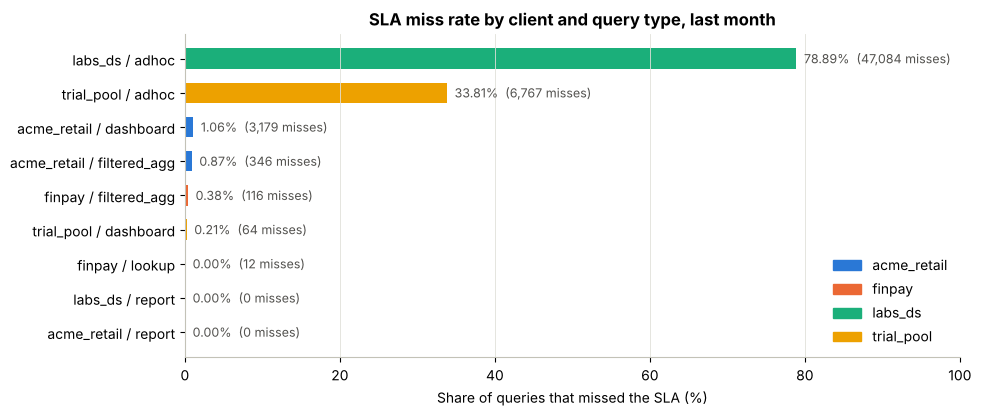

In [15]:
plot_sla = sla_table.reset_index().sort_values("miss_rate_pct")
labels = plot_sla["client_id"] + " / " + plot_sla["query_type"]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(labels, plot_sla["miss_rate_pct"], color=[CLIENT_COLORS[c] for c in plot_sla["client_id"]], height=0.6)
for y, (rate, n) in enumerate(zip(plot_sla["miss_rate_pct"], plot_sla["misses"])):
    ax.text(rate + 1, y, f"{rate:.2f}%  ({int(n):,} misses)", va="center", color="#52514e", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of queries that missed the SLA (%)")
ax.set_title("SLA miss rate by client and query type, last month")
handles = [plt.Rectangle((0, 0), 1, 1, color=CLIENT_COLORS[c]) for c in CLIENT_ORDER]
ax.legend(handles, CLIENT_ORDER, frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

The bar length is the miss rate, and the colour is the client. Only two bars are clearly long, and both are `adhoc`. Everything else is below about 1%.

## E. Traffic patterns

Here I look at how arrivals vary at daily, hourly, 15-minute and 1-minute resolution. I also look for quiet and busy periods that repeat, short bursts and who causes them, and whether similar arrival volumes led to different waiting times.

To turn elapsed seconds into calendar labels, I use:

- `day = arrival_s // 86400` (0 to 29)
- `weekday = WEEKDAYS[day % 7]`, which works because the README fixes `t = 0` at Monday 00:00 US/Eastern
- `hour = (arrival_s % 86400) // 3600` (0 to 23, US/Eastern)
- `bucket_15 = arrival_s // 900`, `minute = arrival_s // 60`

There is one important detail when counting buckets. `groupby(...).size()` only returns buckets that have at least one query. To get correct averages and percentiles, I have to **re-index onto the full range of buckets and fill the empty ones with 0**. Otherwise quiet minutes are silently ignored and the averages come out too high.

In [16]:
queries["day"] = (queries["arrival_s"] // 86400).astype(int)
queries["weekday"] = queries["day"].map(lambda d: WEEKDAYS[d % 7])
queries["is_weekend"] = queries["day"] % 7 >= 5
queries["hour"] = ((queries["arrival_s"] % 86400) // 3600).astype(int)
queries["bucket_15"] = (queries["arrival_s"] // 900).astype(int)
queries["minute"] = (queries["arrival_s"] // 60).astype(int)

n_days = config["duration_s"] // 86400
daily_counts = queries.groupby("day").size().reindex(range(n_days), fill_value=0)
per_15 = queries.groupby("bucket_15").size().reindex(range(n_days * 96), fill_value=0)
per_minute = queries.groupby("minute").size().reindex(range(n_days * 1440), fill_value=0)
assert daily_counts.sum() == per_15.sum() == per_minute.sum() == total_queries

print("Daily arrivals (day: count):")
print(pd.DataFrame({"weekday": [WEEKDAYS[d % 7] for d in daily_counts.index], "arrivals": daily_counts})
      .T.to_string())
print(f"\nWeekday mean {daily_counts[daily_counts.index % 7 < 5].mean():,.0f} per day; "
      f"weekend mean {daily_counts[daily_counts.index % 7 >= 5].mean():,.0f} per day")
summary_res = pd.DataFrame({
    "15-minute buckets": per_15.describe(percentiles=[0.5, 0.9, 0.99]),
    "1-minute buckets": per_minute.describe(percentiles=[0.5, 0.9, 0.99])})
summary_res.round(2)

Daily arrivals (day: count):
day          0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23     24     25     26     27     28     29
weekday     Mon    Tue    Wed    Thu    Fri    Sat    Sun    Mon    Tue    Wed    Thu    Fri    Sat    Sun    Mon    Tue    Wed    Thu    Fri    Sat    Sun    Mon    Tue    Wed    Thu    Fri    Sat    Sun    Mon    Tue
arrivals  31968  32516  31218  30639  30063  12149  10758  30756  30242  34069  30114  29773  12341  10855  31783  30560  31215  30617  30600  12116  10905  32383  33321  32155  33524  30195  12301  10927  32284  33220

Weekday mean 31,510 per day; weekend mean 11,544 per day


,15-minute buckets,1-minute buckets
count,"2,880.000","43,200.000"
mean,272.770,18.180
std,230.740,16.040
min,29.000,0.000
50%,169.000,11.000
90%,612.100,42.000
99%,941.210,65.000
max,"1,398.000",153.000


**Daily:** weekdays have about 30,000 to 34,000 queries and weekends about 10,800 to 12,300. The pattern repeats every week with no clear trend.

**15-minute buckets:** the median is 169 arrivals and the mean is about 273 (pulled up by busy daytime buckets). P99 is about 941, and the maximum is 1,398.

**1-minute buckets:** the median is 11 arrivals and P99 is 65. The busiest minute has **153** arrivals, about 14 times the median minute. Minutes with zero arrivals are included because of the re-indexing.

### E.1 Hour-of-day profile, weekdays vs weekends, by query type

Here I look at the average number of arrivals per hour, separately for weekdays and weekends, and by query type.

Each query type needs a different machine pool. If `adhoc` peaks at a different time from `dashboard`, the pools should be scaled at different times.

I count arrivals per (day, hour, query type), re-index to include the zero cells, and then average over weekdays and over weekend days separately. The result is "the average number of arrivals in that clock hour on a typical weekday".

In [17]:
hourly_full = (queries.groupby(["day", "hour", "query_type"]).size()
               .reindex(pd.MultiIndex.from_product([range(n_days), range(24), QTYPE_ORDER],
                                                   names=["day", "hour", "query_type"]), fill_value=0)
               .rename("arrivals").reset_index())
hourly_full["is_weekend"] = hourly_full["day"] % 7 >= 5
profile = hourly_full.groupby(["is_weekend", "hour", "query_type"])["arrivals"].mean().unstack("query_type")[QTYPE_ORDER]
weekday_profile = profile.loc[False]
weekend_profile = profile.loc[True]
weekday_total = weekday_profile.sum(axis=1)
print(f"Busiest weekday hours: {weekday_total.nlargest(3).index.tolist()} "
      f"(avg {weekday_total.max():,.0f} arrivals/hour)")
print(f"Quietest weekday hours: {weekday_total.nsmallest(3).index.tolist()} "
      f"(avg {weekday_total.min():,.0f} arrivals/hour)")
print(f"Weekend hourly average range: {weekend_profile.sum(axis=1).min():,.0f} to {weekend_profile.sum(axis=1).max():,.0f}")
weekday_profile.round(1).T

Busiest weekday hours: [14, 13, 10] (avg 2,739 arrivals/hour)
Quietest weekday hours: [3, 2, 1] (avg 258 arrivals/hour)
Weekend hourly average range: 184 to 764


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
query_type,,,,,,,,,,,,,,,,,,,,,,,,
lookup,255.000,232.700,209.900,204.500,235.200,278.900,376.200,468.300,586.400,594.400,636.300,659.400,645.500,593.800,596.100,596.800,605.300,572.800,529.600,458.500,424.600,362.900,321.300,277.500
dashboard,38.500,25.900,23.400,26.000,33.500,54.900,141.000,415.000,956.000,"1,291.200","1,566.100","1,460.300","1,036.800","1,351.800","1,447.400","1,319.500","1,238.100",831.400,420.200,237.500,146.900,101.300,65.100,48.900
filtered_agg,29.000,25.600,22.800,23.300,26.500,34.600,58.200,106.100,169.600,225.000,260.100,233.600,201.500,215.900,249.700,239.100,207.100,154.000,99.900,70.800,56.000,50.500,38.500,31.900
adhoc,11.800,5.900,5.000,4.100,3.600,6.500,8.300,13.000,21.400,40.300,78.100,158.000,333.400,474.600,445.700,237.700,323.300,381.500,309.400,259.600,166.800,69.200,35.200,19.700
report,0.000,0.000,17.100,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,167.900,84.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


These figures are for a typical weekday, in US/Eastern time.

- **Quietest hours:** 01:00 to 03:00, with about 260 arrivals per hour on average.
- **Busiest hours:** 14:00, 13:00 and 10:00, with up to about 2,740 arrivals per hour on average, roughly 10 times the quietest hour.
- **Different types peak at different times:**
  - `lookup` (finpay) is spread over the whole day and also appears at weekends.
  - `dashboard` and `filtered_agg` rise from about 07:00, peak between 09:00 and 16:00, and drop off after 17:00.
  - `adhoc` picks up from about 11:00, peaks around **13:00 to 14:00**, and stays high until about 19:00.
  - `report` arrives in two batches: at **02:00** and at **12:00 to 13:00** (I look at these below).
- Weekends are much quieter and mostly `lookup` (with a little of everything else).

For the scheduler, the `adhoc` wave (13:00 to 19:00) explains the afternoon queue in Notebook 3. Pools for interactive work (`dashboard`, `filtered_agg`) should follow office hours, and the long-query pool should grow from late morning.

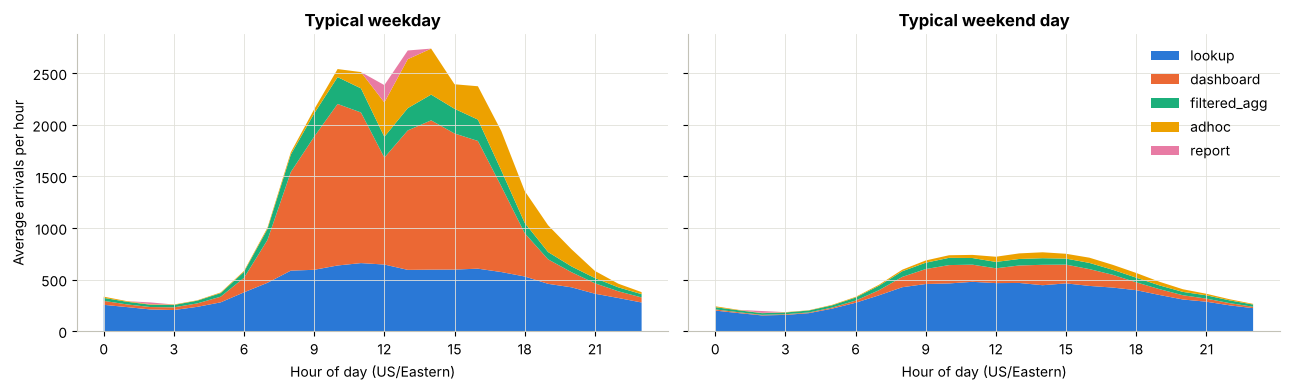

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, prof, title in [(axes[0], weekday_profile, "Typical weekday"), (axes[1], weekend_profile, "Typical weekend day")]:
    ax.stackplot(prof.index, [prof[q] for q in QTYPE_ORDER], colors=[QTYPE_COLORS[q] for q in QTYPE_ORDER],
                 labels=QTYPE_ORDER, linewidth=0)
    ax.set_title(title)
    ax.set_xlabel("Hour of day (US/Eastern)")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("Average arrivals per hour")
axes[1].legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

The height of each coloured band is the average number of arrivals of that type in that hour. By count, weekday traffic is dominated by `dashboard` (orange) and `lookup` (blue), and `adhoc` (yellow) becomes visible from late morning. It is important to remember that count is not work: the thin `adhoc` and `report` bands carry most of the slot-time.

### E.2 Report batches

Here I look at exactly when `report` queries arrive and who sends them.

Reports are long (a 5,400 s benchmark on `mem.xlarge`) and arrive in batches. A batch that lands on a fixed pool takes up many slots for hours.

In [19]:
reports = queries.loc[queries["query_type"] == "report"]
report_timing = reports.groupby(["client_id", "weekday", "hour"]).size().unstack("hour", fill_value=0)
report_timing = report_timing.reindex(pd.MultiIndex.from_product([["acme_retail", "labs_ds"], WEEKDAYS]), fill_value=0)
report_timing = report_timing.loc[:, (report_timing.sum() > 0)]
reports_per_day = reports.groupby(["client_id", "day"]).size().unstack("client_id", fill_value=0)
print("Reports per day (describe):")
print(reports_per_day.describe().round(1).to_string())
report_timing

Reports per day (describe):
client_id  acme_retail  labs_ds
count           30.000   30.000
mean            17.400  185.100
std              4.500  130.100
min              9.000    0.000
25%             15.000   51.200
50%             16.500  220.500
75%             19.000  238.800
max             28.000  480.000


hour             2    12   13
acme_retail Mon  73    0    0
            Tue  80    0    0
            Wed  64    0    0
            Thu  71    0    0
            Fri  88    0    0
            Sat  91    0    0
            Sun  56    0    0
labs_ds     Mon   0  929  465
            Tue   0  948  459
            Wed   0  619  324
            Thu   0  612  329
            Fri   0  585  283
            Sat   0    0    0
            Sun   0    0    0

**`acme_retail` reports** arrive in the **02:00** hour, every day of the week (about 17 per day).

**`labs_ds` reports** arrive between **12:00 and 13:59** on weekdays (several hundred per weekday) and almost never at weekends.

So the `labs_ds` report batch lands exactly when the `adhoc` wave begins, on the same `mem.xlarge` pool. With a 5,400 s benchmark, each report takes up a slot for about 1.5 hours, which helps explain why the `adhoc` queue builds from about 12:30.

For the scheduler, reports have 6 to 12 hour SLAs, so they do not need to start as soon as they arrive. A scheduler could hold them back, or send them to a different pool, so that they do not block 30-minute `adhoc` work.

### E.3 Short bursts: who causes them?

Here I look at the busiest 1-minute buckets, and whether particular clients or query types dominate them.

I take the top 1% of minutes by arrival count. Then I compare each client's and type's share of arrivals in those minutes with its share of all arrivals. If a share is much higher in bursts than overall, that client or type *drives* the bursts.

In [20]:
burst_threshold = per_minute.quantile(0.99)
burst_minutes = per_minute.index[per_minute >= burst_threshold]
in_burst = queries["minute"].isin(burst_minutes)
burst_compare = pd.DataFrame({
    "share of all arrivals (%)": queries.groupby(["client_id", "query_type"]).size() / total_queries * 100,
    "share of arrivals in top-1% minutes (%)": queries.loc[in_burst].groupby(["client_id", "query_type"]).size()
                                                / in_burst.sum() * 100}).fillna(0)
top_minutes = per_minute.nlargest(8)
top_detail = (queries.loc[queries["minute"].isin(top_minutes.index)]
              .groupby(["minute", "client_id", "query_type"]).size().unstack(["client_id", "query_type"], fill_value=0))
top_detail.insert(0, "when", [f"day {m // 1440} ({WEEKDAYS[(m // 1440) % 7]}) {(m % 1440) // 60:02d}:{m % 60:02d}"
                              for m in top_detail.index])
print(f"Top-1% minute threshold: {burst_threshold:.0f} arrivals/minute; {len(burst_minutes)} minutes qualify")
display(burst_compare.round(2).sort_values("share of arrivals in top-1% minutes (%)", ascending=False))
top_detail

Top-1% minute threshold: 65 arrivals/minute; 448 minutes qualify


,,share of all arrivals (%),share of arrivals in top-1% minutes (%)
client_id,query_type,,
acme_retail,dashboard,38.130,69.410
finpay,lookup,38.210,16.850
labs_ds,adhoc,7.600,4.840
acme_retail,filtered_agg,5.080,3.920
trial_pool,dashboard,3.820,1.720
finpay,filtered_agg,3.850,1.420
trial_pool,adhoc,2.550,1.090
labs_ds,report,0.710,0.760
acme_retail,report,0.070,0.000


client_id                 when acme_retail              finpay              trial_pool labs_ds trial_pool
query_type                       dashboard filtered_agg lookup filtered_agg  dashboard   adhoc      adhoc
minute                                                                                                   
20698       day 14 (Mon) 08:58         112            4     15            0          0       0          0
20700       day 14 (Mon) 09:00         134            2      9            2          1       0          0
20701       day 14 (Mon) 09:01         144            0      9            0          0       0          0
20702       day 14 (Mon) 09:02         127            3     11            0          0       1          0
35198       day 24 (Thu) 10:38          87           17      5            0          0       0          1
35202       day 24 (Thu) 10:42          92           13     13            0          1       0          0
35203       day 24 (Thu) 10:43          95            8     20            0          1       0          1
35207       day 24 (Thu) 10:47          88            1     15            2          0       1          0

The top 1% of minutes (448 minutes) each have at least 65 arrivals.

In those minutes, **`acme_retail / dashboard`** makes up about 69% of arrivals, compared with 38% overall, so it is the main source of short bursts. `finpay / lookup` appears less than usual (17% against 38%), because it is spread evenly over the day.

The very busiest minutes (112 to 144 arrivals, mostly dashboards) are on **day 14 (a Monday) around 09:00**, and there is a second group on **day 24 (a Thursday) from 10:38 to 10:47**.

I wanted to know whether the day-14 burst caused any harm. The miss counts by day (next cell) say it did not. Dashboards are short (about 3 seconds), so a few minutes at about 130 per minute are absorbed by the 48 `std.large` slots. The day-24 group is different, as the next section shows.

### E.4 The day-24 event: a `filtered_agg` surge

Here I look at what changed in the traffic on day 24 between 09:00 and 11:00, when Notebook 3 found the `std.large` pool full and over 1,000 dashboards waiting.

I compare day 24's arrivals per hour, by client and type, with the median of the same hours on the other weekdays, and I count the misses per day by query type.

In [21]:
weekday_days = [d for d in range(n_days) if d % 7 < 5 and d != 24]
window = queries.loc[queries["hour"].between(8, 11)]
per_day_hour = window.groupby(["day", "hour", "client_id", "query_type"]).size()
day24 = per_day_hour.loc[24].unstack(["client_id", "query_type"], fill_value=0)
typical = (per_day_hour.loc[weekday_days].unstack(["client_id", "query_type"], fill_value=0)
           .groupby(level="hour").median())
compare_cols = [("acme_retail", "filtered_agg"), ("finpay", "filtered_agg"), ("acme_retail", "dashboard")]
surge = pd.concat({"day 24": day24[compare_cols], "median other weekdays": typical[compare_cols]}, axis=1)
misses_by_day = queries.loc[queries["missed"] == 1].groupby(["day", "query_type"]).size().unstack(fill_value=0) \
                       .reindex(index=range(n_days), columns=QTYPE_ORDER, fill_value=0)
print("Dashboard misses on day 24:", misses_by_day.loc[24, "dashboard"],
      "| dashboard misses on all other days:", misses_by_day["dashboard"].drop(24).sum())
print("filtered_agg misses on day 24:", misses_by_day.loc[24, "filtered_agg"],
      "| on all other days:", misses_by_day["filtered_agg"].drop(24).sum())
surge

Dashboard misses on day 24: 3242 | dashboard misses on all other days: 1
filtered_agg misses on day 24: 167 | on all other days: 295


day 24                          median other weekdays                         
client_id   acme_retail       finpay acme_retail           acme_retail       finpay acme_retail
query_type filtered_agg filtered_agg   dashboard          filtered_agg filtered_agg   dashboard
hour                                                                                           
8                   107           51         743               110.000       55.000     795.000
9                   262           63        1122               153.000       63.000   1,140.000
10                  581           49        2677               183.000       61.000   1,320.000
11                  167           67        2254               166.000       65.000   1,228.000

In the **10:00 hour of day 24**, `acme_retail` sent **581 `filtered_agg` queries, compared with a typical 183** (about 3.2 times as many), and it had already sent 262 against a typical 153 in the 09:00 hour. In the same hours, its **dashboards roughly doubled** (2,677 against a typical 1,320 at 10:00). `finpay`'s traffic was normal.

Each `filtered_agg` takes about 240 seconds on `std.large`, so the surge filled the 48-slot pool. The `dashboard` queries (3 seconds each, with a 10-second SLA) had to wait behind them in the same FIFO queue.

**3,242 of the month's 3,243 `dashboard` misses happened on day 24.** The only other dashboard miss was in the start-up minutes of day 0. Day 24 also accounts for 167 of the 462 `filtered_agg` misses.

My interpretation is that a fairly small, unannounced change in one client's traffic caused a burst of SLA misses for a *different* query type that shared the same pool and queue. This is exactly the "traffic can change with no notice" risk the README describes.

For the scheduler, this means three things: (1) short-SLA work should be kept separate or given priority, so it does not get stuck behind long queries in one FIFO queue; (2) the scheduler should react quickly when a pool's queue grows; and (3) it should keep some spare capacity on pools that serve seconds-level SLAs.

### E.5 Do similar arrival volumes give similar waiting times?

Here I check whether the number of arrivals in an hour predicts the waiting time for `adhoc`, which is the type that waits the most.

If waiting only depended on current arrivals, a scheduler could scale based on the arrival rate. But if the same number of arrivals sometimes means no wait and sometimes means hours of waiting, then the *backlog* (work already queued or running) matters more.

For each (day, hour), I count the `adhoc` arrivals and take the median wait of the `adhoc` queries that arrived in that hour. I then group the hours into bands with similar arrival counts and look at the range of median waits within each band.

In [22]:
adhoc = queries.loc[queries["query_type"] == "adhoc"]
adhoc_hourly = adhoc.groupby(["day", "hour"]).agg(arrivals=("query_id", "size"), median_wait_s=("wait_s", "median"))
adhoc_hourly["arrival_band"] = pd.cut(adhoc_hourly["arrivals"], [0, 50, 100, 200, 300, 500, 1000])
band_summary = adhoc_hourly.groupby("arrival_band", observed=True)["median_wait_s"].agg(
    hours="size", min="min", median="median", max="max")
print("Spearman rank correlation, hourly adhoc arrivals vs median adhoc wait:",
      round(adhoc_hourly["arrivals"].corr(adhoc_hourly["median_wait_s"], method="spearman"), 3))
(band_summary / pd.Series({"hours": 1, "min": 60, "median": 60, "max": 60})).round(1).rename(
    columns={"min": "min_wait_min", "median": "median_wait_min", "max": "max_wait_min"})

Spearman rank correlation, hourly adhoc arrivals vs median adhoc wait: 0.69


,hours,min_wait_min,median_wait_min,max_wait_min
arrival_band,,,,
"(0, 50]",419.000,0.000,0.000,234.800
"(50, 100]",75.000,0.000,0.000,288.600
"(100, 200]",45.000,0.000,0.000,264.400
"(200, 300]",72.000,0.000,118.000,436.000
"(300, 500]",88.000,0.000,142.900,453.000
"(500, 1000]",14.000,3.200,209.000,451.300


The waits here are shown in minutes.

Overall, arrivals and waits go up together (Spearman about 0.69, so busier hours tend to wait longer).

But within the **same arrival band**, the median wait varies a lot. Hours with 50 to 100 `adhoc` arrivals had a median wait of 0 in most cases, but up to about 4.8 hours in others. Hours with 200 to 300 arrivals ranged from 0 to over 7 hours. Quiet hours in the evening wait because of the backlog left over from the afternoon, while busy hours early in the wave start with an empty queue.

So waiting depends on the backlog that has built up and on what else is using the pool (reports and earlier `adhoc` queries), not just on how many queries arrive now. A scheduler should scale based on **queued work** (the estimated slot-seconds waiting and running in each pool), not on arrival counts alone.

## F. Query template analysis and runtime prediction

Here I look at how templates repeat, how they map to clients and types, how much runtime varies within a template, and whether template history could be used to predict runtimes while the scheduler is running.

The README says the runtime is `benchmark * a per-query factor` that the scheduler does not know in advance. But it also says that queries with the same `template_id` are repeats of the same SQL. If repeats have similar factors, the scheduler can learn them from completed queries and make much better routing and capacity decisions.

The key quantity is `multiplier = run_s / benchmark(query_type, machine type it ran on)`. The engine calculates the runtime as `runtime_matrix_s[query_type][instance_type] * multiplier`, so the multiplier does not depend on the machine type. A scheduler can calculate it in `on_complete(query, instance_id, runtime_s)` using the config matrix, which only uses information the scheduler is allowed to see.

In [23]:
template_stats = queries.groupby("template_id").agg(
    client_id=("client_id", "first"), query_type=("query_type", "first"),
    n_clients=("client_id", "nunique"), n_types=("query_type", "nunique"),
    count=("query_id", "size"), mult_mean=("multiplier", "mean"), mult_std=("multiplier", "std"))
template_stats["mult_cv"] = template_stats["mult_std"] / template_stats["mult_mean"]
print(f"Unique templates: {len(template_stats):,}")
print("Templates used by more than one client or query type:",
      int(((template_stats["n_clients"] > 1) | (template_stats["n_types"] > 1)).sum()))
print("\nQueries per template (distribution):")
print(template_stats["count"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1).to_string())
print("\nTemplates and repetition by client / type:")
by_ct = template_stats.groupby(["client_id", "query_type"]).agg(
    templates=("count", "size"), queries=("count", "sum"), median_repeats=("count", "median"),
    max_repeats=("count", "max"))
display(by_ct)
print("Most repeated templates:")
template_stats.sort_values("count", ascending=False).head(8)[["client_id", "query_type", "count", "mult_mean", "mult_cv"]]

Unique templates: 11,537
Templates used by more than one client or query type: 0

Queries per template (distribution):
count   11,537.000
mean        68.100
std        678.900
min          1.000
25%          8.000
50%         26.000
75%         46.000
90%         97.000
99%        616.200
max     58,913.000

Templates and repetition by client / type:


templates  queries  median_repeats  max_repeats
client_id   query_type                                                   
acme_retail dashboard           400   299513         173.000        58913
            filtered_agg        300    39929          55.000         4794
            report               25      523          14.000          103
finpay      filtered_agg        200    30230          62.000         4025
            lookup             5000   300128          38.000         4133
labs_ds     adhoc              2992    59684           9.000         2972
            report              150     5553          20.000          599
trial_pool  adhoc              1970    20017           6.000          699
            dashboard           500    29990          18.000         4496

Most repeated templates:


,client_id,query_type,count,mult_mean,mult_cv
template_id,,,,,
ac-db-0000,acme_retail,dashboard,58913,1.186,0.080
ac-db-0001,acme_retail,dashboard,27432,1.082,0.081
ac-db-0002,acme_retail,dashboard,17546,1.005,0.080
ac-db-0003,acme_retail,dashboard,12924,0.871,0.081
ac-db-0004,acme_retail,dashboard,9944,1.412,0.080
ac-db-0005,acme_retail,dashboard,8124,1.027,0.080
ac-db-0006,acme_retail,dashboard,6956,1.144,0.080
ac-db-0007,acme_retail,dashboard,5898,1.133,0.081


There are **11,537 templates**, and **each template belongs to exactly one client and one query type**. The IDs even encode this: for example, `fp-lk-...` is finpay lookup and `lb-ah-...` is labs\_ds adhoc.

How often templates repeat varies. `acme_retail` dashboard templates repeat the most (a median of 173 times), `filtered_agg` templates about 55 to 62 times, and `adhoc` templates the least (a median of 9 for `labs_ds` and 6 for `trial_pool`). This makes sense, because ad-hoc analysis is more varied.

The distribution is very skewed: the median template is used 26 times, but the most common one (`ac-db-0000`) is used 58,913 times.

### F.1 How much does runtime vary within a template?

Here I compare how much the multiplier varies within templates with how much it varies across a whole query type.

I use the **coefficient of variation (CV)**, which is the standard deviation divided by the mean. It shows the spread as a fraction of the average, so it can be compared across types with different runtimes. A CV of 0.08 means a typical deviation of about 8% from the mean.

In [24]:
cv_compare = pd.DataFrame({
    "overall multiplier CV (whole type)": queries.groupby("query_type")["multiplier"].agg(lambda s: s.std() / s.mean()),
    "mean within-template CV": template_stats.groupby("query_type")["mult_cv"].mean(),
    "multiplier P1": queries.groupby("query_type")["multiplier"].quantile(0.01),
    "multiplier P99": queries.groupby("query_type")["multiplier"].quantile(0.99),
}).reindex(QTYPE_ORDER)
cv_compare.round(3)

,overall multiplier CV (whole type),mean within-template CV,multiplier P1,multiplier P99
query_type,,,,
lookup,0.170,0.079,0.673,1.480
dashboard,0.214,0.079,0.552,1.744
filtered_agg,0.520,0.080,0.396,2.735
adhoc,0.814,0.076,0.181,5.182
report,0.302,0.079,0.474,1.981


Across a whole type, the multipliers vary a lot. The CV is about **0.81 for `adhoc`** and **0.52 for `filtered_agg`**, and the range from P1 to P99 covers a factor of ten or more.

**Within a template, the CV is only about 0.08** for every type. Repeats of the same SQL run within roughly plus or minus 8% of each other.

So the template explains most of the variation in runtime. The benchmark matrix tells me the *type's* typical runtime, while the template history tells me *this query's* runtime.

### F.2 Would an online template-history predictor have helped?

Here I check how accurate a simple, legitimate online predictor would have been, compared with using the benchmark alone.

The predictor only uses information that would have been available at the time:

- For a query arriving at time `t`, it looks at all earlier queries **with the same template that had already completed before `t`** (`end_s < t`), and takes the mean of their multipliers. The predicted runtime on machine type M is `benchmark(type, M) * predicted multiplier`.
- If no query with the same template has completed yet, the predictor has no history (I report how often this happens). A scheduler would then fall back to the benchmark (multiplier 1.0).

The baseline is the benchmark only, which means a multiplier of 1.0.

To measure the error, I use the absolute percentage error, `abs(predicted - actual) / actual`, and report its median per type. Because the predicted and actual multipliers are both relative to the same benchmark, this is the same as the runtime prediction error.

To implement it, for each template I sort the completed queries by `end_s`, build a running total of multipliers, and use `np.searchsorted` to find how many had completed before each query arrived. This avoids a slow row-by-row loop and makes sure no information from the future leaks in.

In [25]:
predicted = pd.Series(np.nan, index=queries.index)
for _, group in queries.groupby("template_id", sort=False):
    order = np.argsort(group["end_s"].to_numpy())
    ends = group["end_s"].to_numpy()[order]
    cumulative = np.concatenate([[0.0], np.cumsum(group["multiplier"].to_numpy()[order])])
    n_before = np.searchsorted(ends, group["arrival_s"].to_numpy(), side="left")   # completed strictly before arrival
    predicted.loc[group.index] = np.where(n_before > 0, cumulative[n_before] / np.maximum(n_before, 1), np.nan)
queries["predicted_multiplier"] = predicted

has_history = queries["predicted_multiplier"].notna()
queries["err_template"] = (queries["predicted_multiplier"] - queries["multiplier"]).abs() / queries["multiplier"]
queries["err_benchmark"] = (1.0 - queries["multiplier"]).abs() / queries["multiplier"]
pred_eval = pd.DataFrame({
    "share with history (%)": queries.groupby("query_type")["predicted_multiplier"].apply(lambda s: s.notna().mean() * 100),
    "median APE, template history (%)": queries.loc[has_history].groupby("query_type")["err_template"].median() * 100,
    "median APE, benchmark only (%)": queries.loc[has_history].groupby("query_type")["err_benchmark"].median() * 100,
    "P90 APE, template history (%)": queries.loc[has_history].groupby("query_type")["err_template"].quantile(0.9) * 100,
    "P90 APE, benchmark only (%)": queries.loc[has_history].groupby("query_type")["err_benchmark"].quantile(0.9) * 100,
}).reindex(QTYPE_ORDER)
print(f"Queries with at least one completed sibling before arrival: {has_history.mean():.1%}")
pred_eval.round(1)

Queries with at least one completed sibling before arrival: 98.5%


,share with history (%),"median APE, template history (%)","median APE, benchmark only (%)","P90 APE, template history (%)","P90 APE, benchmark only (%)"
query_type,,,,,
lookup,98.300,5.600,11.200,13.700,27.900
dashboard,99.700,5.400,14.100,13.400,33.900
filtered_agg,99.300,5.500,36.700,13.500,77.400
adhoc,93.300,5.700,46.500,14.300,144.900
report,94.300,5.600,19.100,13.900,49.300


About **98.5%** of queries had at least one earlier query with the same template already completed when they arrived (93% to 94% for `adhoc` and `report`, whose templates repeat less). So history is almost always available after a short warm-up.

With template history, the **median error is about 5% to 6% for every query type**. With the benchmark alone, it is 11% for `lookup`, 14% for `dashboard`, 19% for `report`, 37% for `filtered_agg` and **46% for `adhoc`**. The P90 errors show the same picture in the tail.

What I cannot conclude is that the same accuracy will hold in unseen scenarios. The README warns that the runtime matrix can change in the middle of the month. Because the predictor learns a *multiplier relative to the current benchmark*, it would keep working if the matrix changed for all queries of a type, but the scheduler should keep updating it as new completions come in.

For the scheduler, predicted runtimes make three things possible: (1) spotting heavy `filtered_agg` queries that will miss a 10 to 15 minute SLA on `std.large` and sending them to `mem.xlarge`; (2) estimating the queued work in each pool for scaling; and (3) deciding whether a `report` can meet its deadline on a cheaper machine. A practical online version keeps a running count and mean of the observed multipliers for each template, updated in `on_complete`.

## G. Historical machine routing

Here I look at which machine type served each query type, with the counts, runtimes, waits and misses for each assignment.

Routing is one of the scheduler's three decisions. Understanding last month's policy tells me what to change, but it does not mean the policy was good.

In [26]:
routing = pd.crosstab(queries["query_type"], queries["instance_type"]).reindex(index=QTYPE_ORDER, columns=TYPE_ORDER, fill_value=0)
route_perf = queries.groupby(["query_type", "instance_type"]).agg(
    queries=("query_id", "size"), benchmark_s=("benchmark_s", "first"),
    mean_run_s=("run_s", "mean"), median_run_s=("run_s", "median"),
    p90_run_s=("run_s", lambda s: s.quantile(0.9)),
    mean_wait_s=("wait_s", "mean"), median_wait_s=("wait_s", "median"),
    misses=("missed", "sum"), miss_rate_pct=("missed", lambda s: s.mean() * 100))
cheapest_od = {qt: min(config["instance_types"], key=lambda it: config["runtime_matrix_s"][qt][it]
                       * config["instance_types"][it]["on_demand_usd_per_hr"] / config["instance_types"][it]["slots"])
               for qt in QTYPE_ORDER}
fastest = {qt: min(config["runtime_matrix_s"][qt], key=config["runtime_matrix_s"][qt].get) for qt in QTYPE_ORDER}
print("Routing counts (query type x machine type):")
display(routing)
print("Cheapest on-demand machine per type (benchmark x price / slots):", cheapest_od)
print("Fastest machine per type:", fastest)
route_perf

Routing counts (query type x machine type):


instance_type,std.small,std.large,mem.xlarge
query_type,,,
lookup,300128,0,0
dashboard,0,329503,0
filtered_agg,0,70159,0
adhoc,0,0,79701
report,0,0,6076


Cheapest on-demand machine per type (benchmark x price / slots): {'lookup': 'std.small', 'dashboard': 'std.large', 'filtered_agg': 'std.large', 'adhoc': 'mem.xlarge', 'report': 'mem.xlarge'}
Fastest machine per type: {'lookup': 'mem.xlarge', 'dashboard': 'mem.xlarge', 'filtered_agg': 'mem.xlarge', 'adhoc': 'mem.xlarge', 'report': 'mem.xlarge'}


,,queries,benchmark_s,mean_run_s,median_run_s,p90_run_s,mean_wait_s,median_wait_s,misses,miss_rate_pct
query_type,instance_type,,,,,,,,,
adhoc,mem.xlarge,79701,450.000,591.416,470.520,"1,141.560","7,316.613","6,858.433",53851,67.566
dashboard,std.large,329503,3.000,3.232,3.217,4.055,4.414,0.000,3243,0.984
filtered_agg,std.large,70159,240.000,254.770,213.168,455.966,3.728,0.000,462,0.659
lookup,std.small,300128,0.300,0.304,0.299,0.372,0.003,0.000,12,0.004
report,mem.xlarge,6076,"5,400.000","5,773.858","5,526.360","8,122.950","4,853.616","4,171.928",0,0.000


**Each query type went to exactly one machine type:** `lookup` to `std.small`, `dashboard` and `filtered_agg` to `std.large`, and `adhoc` and `report` to `mem.xlarge`.

That mapping is the same as the **cheapest on-demand machine for each query type** by benchmark cost (`benchmark * price / slots`). This matches the `LegacyStatic` routing in `baselines.py`.

The observed median runtimes are close to the benchmark of the assigned machine. The P90 runtimes are about 25% (`lookup`) to 150% (`adhoc`) above it, which is the multiplier tail.

All the waiting and nearly all the misses are on `mem.xlarge` (the `adhoc` queue), plus the day-24 `std.large` episode.

There are some things the historical policy never did: it never sent overflow to another pool, never prioritised by deadline or client value, and never treated heavy queries differently. Sending each query to its cheapest machine is reasonable *when the pool has capacity*, but with a fixed pool, the cheapest machine became the slowest path for `adhoc`.

## H. Retries and interruptions

Here I look at the number of attempts per query, how it relates to market and query type, and whether there is any evidence of restarts.

From `engine.py`, a query is only restarted if the machine it runs on is terminated while it is running. This can happen either through a **spot interruption** (random, at the rate `spot_interruptions_per_hr`, with a `spot_notice_s` warning) or when the scheduler calls `terminate(id, drain=False)`. The query then becomes pending again, and its `attempts` counter goes up when it is next started. `start_s` and `run_s` in the log only describe the final attempt. The partial work is lost, but it was still billed and counted in `busy_slot_s`.

In [27]:
attempts_table = pd.crosstab([queries["market"], queries["query_type"]], queries["attempts"])
print("Queries with more than one attempt:", int((queries["attempts"] > 1).sum()))
print("Instances used, by market:", queries.groupby("market")["instance_id"].nunique().to_dict())
attempts_table

Queries with more than one attempt: 0
Instances used, by market: {'on_demand': 14}


attempts                     1
market    query_type          
on_demand adhoc          79701
          dashboard     329503
          filtered_agg   70159
          lookup        300128
          report          6076

Every query ran exactly once (`attempts = 1`), all on on-demand machines. Since no spot machines were used and no machine was terminated before the end (Notebook 2), **there is no evidence of interruptions or restarts, and none could have happened**.

What I cannot conclude is anything about how often spot machines would be interrupted in practice, or how much work would be lost. That has to be worked out from the config. For example, `mem.xlarge` spot has 0.08 interruptions per hour, which means an average of 12.5 hours between interruptions per machine. So a 5,400 s report has roughly a `1 - exp(-0.08 * 1.5)` chance, or about 11%, of being interrupted on each attempt (more when its multiplier is larger), and it loses all its progress if that happens.

## Summary of findings

**Data quality.** There were 785,567 completed queries, with no missing values, no duplicates, no drops and no retries, all on on-demand machines. I checked every column definition against the engine.

**Workload.** acme\_retail (dashboards) and finpay (lookups) send about 85% of the queries, while labs\_ds and trial\_pool send the long `adhoc`/`report` work that takes up most of the slot-time.

**Waiting and execution.** Short query types almost never waited. `adhoc` waited a median of about 1.9 hours (about 2.25 hours for `labs_ds`), and `report` about 1.2 hours.

**SLA.** There were 57,568 misses (7.3%). `labs_ds/adhoc` missed about 79% of the time (about \$9.4k uncapped, capped at **\$900**). acme\_retail owed about \$491, finpay about \$59 and trial\_pool \$0. Total miss penalties were about **\$1,450**, and drop penalties were \$0. About 95% of misses were caused by waiting alone.

**Traffic.** There is a strong weekly cycle (weekends have about a third of the weekday traffic) and a daily cycle (quiet from 01:00 to 04:00, busy from 09:00 to 17:00). `adhoc` peaks between 13:00 and 19:00, `labs_ds` reports arrive between 12:00 and 14:00 on weekdays, and `acme_retail` reports arrive at 02:00 every day. Short bursts are mostly acme dashboards. One unannounced acme surge (day 24 at 10:00, with `filtered_agg` about 3 times normal and dashboards about 2 times) caused 3,242 dashboard misses.

**Templates.** Each template belongs to one client and type. The runtime CV within a template is about 8%, compared with up to 81% across a type. An online template-mean predictor gets a median error of about 5% to 6%, compared with 11% to 46% for the benchmark.

**Routing.** Each type went to its cheapest on-demand machine, with one machine type per query type, a FIFO queue per pool, and no overflow or priorities.

**What this means for the scheduler**

1. Reduce `adhoc` queueing: scale the long-query capacity with the afternoon wave, allow overflow to `std.large`, and prioritise by deadline and penalty (paying clients before `trial_pool`).
2. Stop short-SLA work from being blocked by long work in the same queue.
3. Learn the multiplier of each template online, and use it to route heavy queries and to estimate queued work.
4. Use the spare time reports have (6 to 12 hours) to run them on cheaper capacity or at less busy times.
5. Remember that once a penalty cap is reached, extra misses are free. Account for this explicitly and openly.